<a href="https://colab.research.google.com/github/houmanhaghi/Gold3nMind/blob/main/3-Coin2Bullion/Coin2Bullion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔰 Descriptions of Project

As you may know, the price of gold (Au) and its derivations is not stable and too many events and news can effect it. One of the most popular actions is to increase the amount of gold in gram not in cose. This goal can be acheived by changing it to its different derivations but in perticular and appropriate time.

# ✅ Definition of Done

The purpose of this project is to forecast the best time of converting gold coin (Emami coin) to bullion and againts actions.

I want to use the history of prices and using bubble formulas to gain this golden times.


## Data collecting


In [2]:
! pip install persiantools

In [40]:
import os
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from persiantools.jdatetime import JalaliDate
from datetime import timedelta
from datetime import datetime, timedelta

calling API — only once — or use from downloaded csv files

website: ```https://www.navasan.tech/```


Telegram Bot: (Free API) ```https://t.me/navasan_contact_bot
```

In [36]:

MODE = 'STORAGE'      # API / STORAGE

market = dict()

items = [
    'xau',          # اونس طلا
    'usd_xau',      # اونس جهانی طلا
    'sekkeh',       # سکه امامی
    'bahar',        # سکه بهار آزادی
    'nim',          # نیم سکه
    'rob',          # ربع سکه
    'gerami',       # سکه گرمی
    'abshodeh',     # مثقال طلای آبشده
    '18ayar',       # گرم طلای 18 عیار
    'bub_18ayar',   # حباب طلای 18
    'bub_abshodeh', # حباب مثقال طلای آبشده
    'bub_bahar',    # حباب سکه بهار آزادی
    'bub_gerami',   # حباب سکه گرمی
    'bub_nim',      # حباب نیم سکه
    'bub_rob',      # حباب ربع سکه
    'bub_sekkeh',   # حباب سکه امامی

]


for item in items:
  if MODE == 'API':
    API_KEY = "freeAOjTDjWzkIwGioUijVGW2Xq0ZyBd"
    Start_Day = "1397-01-01"
    today = JalaliDate.today().strftime("%Y-%m-%d")

    if not os.path.exists('data'):
      os.makedirs('data')

    url = f"https://api.navasan.tech/ohlcSearch/?api_key={API_KEY}&item={item}&start={Start_Day}&end={today}"
    response = requests.get(url)
    print(f"Status Code for {item}: {response.status_code}")
    if response.status_code == 200:
      try:
        data = response.json()
        df = pd.DataFrame(data)
        market[item] = df
        df.to_csv(f"data/{item}.csv", index=False)
        print(f"{item} data saved successfully.")

      except requests.exceptions.JSONDecodeError:
        print(f"Could not decode JSON for {item}. Response text: {response.text}")

      except Exception as e:
        print(f"An error occurred while processing {item}: {e}")


  elif MODE == 'STORAGE':
    csv_path = f"data/{item}.csv"
    if os.path.exists(csv_path):
      try:
        df = pd.read_csv(csv_path)
        market[item] = df
        print(f"{item} data loaded successfully.")

      except Exception as e:
        print(f"An error occurred while loading {item} data: {e}")
    else:
      print(f"{item} data not found.")




xau data loaded successfully.
usd_xau data loaded successfully.
sekkeh data loaded successfully.
bahar data loaded successfully.
nim data loaded successfully.
rob data loaded successfully.
gerami data loaded successfully.
abshodeh data loaded successfully.
18ayar data loaded successfully.
bub_18ayar data loaded successfully.
bub_abshodeh data loaded successfully.
bub_bahar data loaded successfully.
bub_gerami data loaded successfully.
bub_nim data loaded successfully.
bub_rob data loaded successfully.
bub_sekkeh data loaded successfully.


## Data Cleaning

Prices are in Dollar or Toman

In [39]:
original_market = market.copy()



def j2g(jdate_str: str):
    # expects "YYYY-MM-DD" (Jalali); returns pandas Timestamp
    try:
        y, m, d = map(int, [jdate_str[:4], jdate_str[5:7], jdate_str[8:10]])
        g = JalaliDate(y, m, d).to_gregorian()
        return pd.to_datetime(g)
    except Exception:
        return pd.NaT

for name, df in list(market.items()):
    # drop missing columns quietly; keep first occurrence per 'date'
    df = df.drop(columns=['timestamp', 'open', 'high', 'low'], errors='ignore')
    df = df.drop_duplicates(subset='date', keep='first').sort_values('date').reset_index(drop=True)

    # add Gregorian date
    if 'date' in df.columns:
        df['gregorian_date'] = df['date'].astype(str).apply(j2g)
        df = df[['close',  'date', 'gregorian_date']]
    else:
        df = df[['close']]


    market[name] = df

    print(f'Name: {name}')
    print(df.tail(1))
    print('\n\n')


Name: xau
          close        date gregorian_date
2283  407944270  1404-07-05     2025-09-27



Name: usd_xau
         close        date gregorian_date
2271  3759.855  1404-07-05     2025-09-27



Name: sekkeh
          close        date gregorian_date
2273  108100000  1404-07-05     2025-09-27



Name: bahar
         close        date gregorian_date
2273  99800000  1404-07-05     2025-09-27



Name: nim
         close        date gregorian_date
2273  56300000  1404-07-05     2025-09-27



Name: rob
         close        date gregorian_date
2273  33200000  1404-07-05     2025-09-27



Name: gerami
         close        date gregorian_date
2273  17000000  1404-07-05     2025-09-27



Name: abshodeh
         close        date gregorian_date
2269  43147000  1404-07-05     2025-09-27



Name: 18ayar
        close        date gregorian_date
2272  9960520  1404-07-05     2025-09-27



Name: bub_18ayar
       close        date gregorian_date
2286  123740  1404-07-05     2025-09-27



Name:

## Golden Mind Logics

Apply different popular ways



In [ ]:
### Validation Variables



### sekke / 18ayar

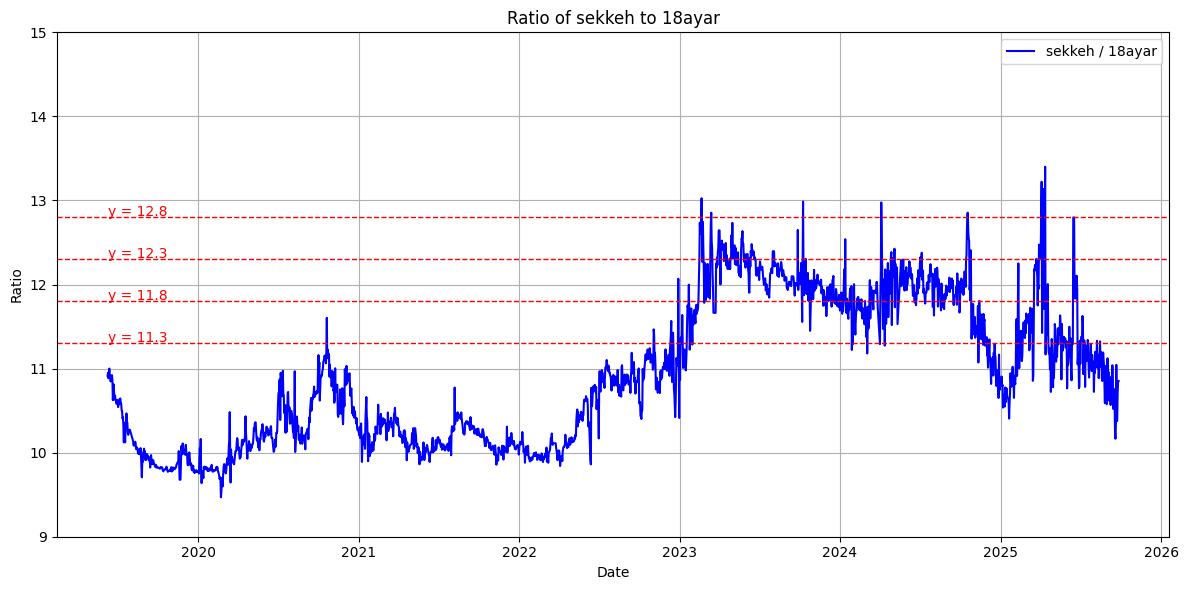

In [42]:
ratio = market['sekkeh']['close'] / market['18ayar']['close']
ratio.index = pd.to_datetime(market['sekkeh']['gregorian_date'])
ratio_df = pd.DataFrame({
    'ratio': ratio
}, index=ratio.index)


plt.figure(figsize=(12, 6))
plt.plot(ratio.index, ratio, label='sekkeh / 18ayar', color='blue')

# Focus on the desired y-range
plt.ylim(9, 15)

# Add the horizontal reference lines
for y in [11.3, 11.8, 12.3, 12.8]:
    plt.axhline(y=y, color='red', linestyle='--', linewidth=1)
    plt.text(ratio.index.min(), y + 0.02, f'y = {y}', color='red')

plt.xlabel('Date')
plt.ylabel('Ratio')
plt.title('Ratio of sekkeh to 18ayar')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



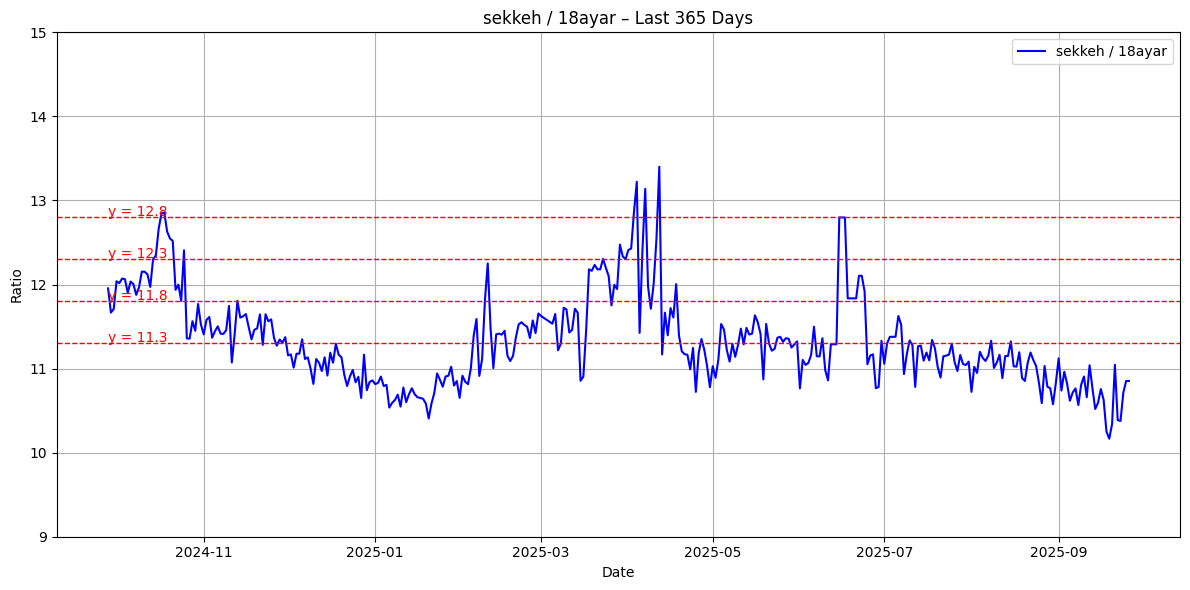

In [44]:
### Last year only

ratio.index = pd.to_datetime(ratio.index)
last_365 = ratio[ratio.index >= (pd.Timestamp.today() - pd.Timedelta(days=365))]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(last_365.index, last_365, label='sekkeh / 18ayar', color='blue')

plt.ylim(9, 15)

# Add guide lines
for y in [11.3, 11.8, 12.3, 12.8]:
    plt.axhline(y=y, color='red', linestyle='--', linewidth=1)
    plt.text(last_365.index.min(), y + 0.02, f'y = {y}', color='red')

plt.xlabel('Date')
plt.ylabel('Ratio')
plt.title('sekkeh / 18ayar – Last 365 Days')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



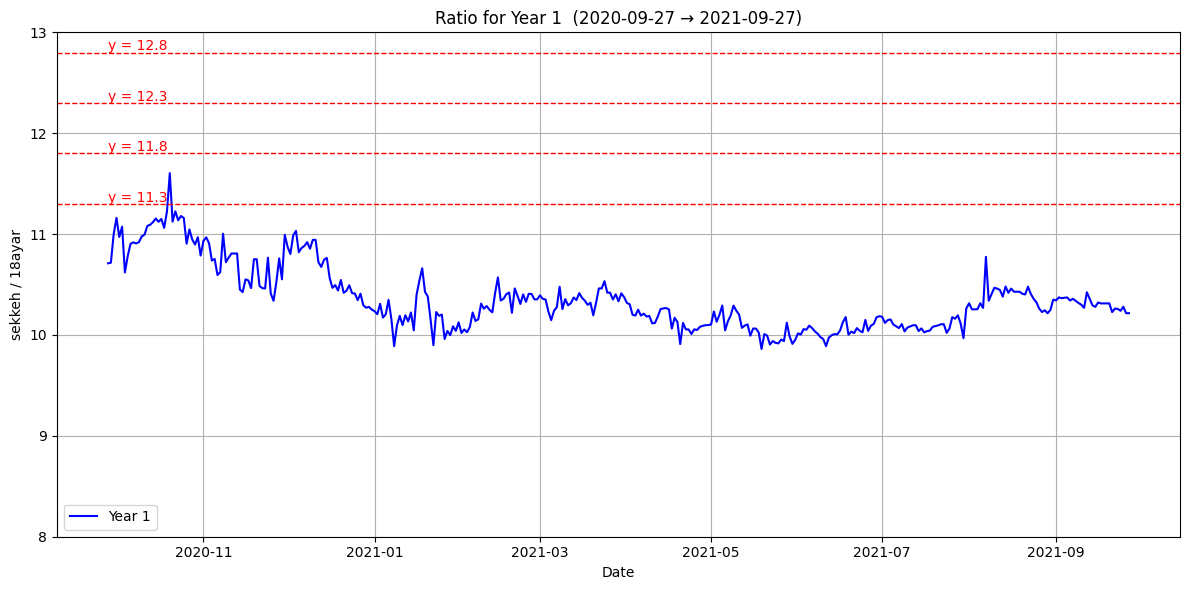

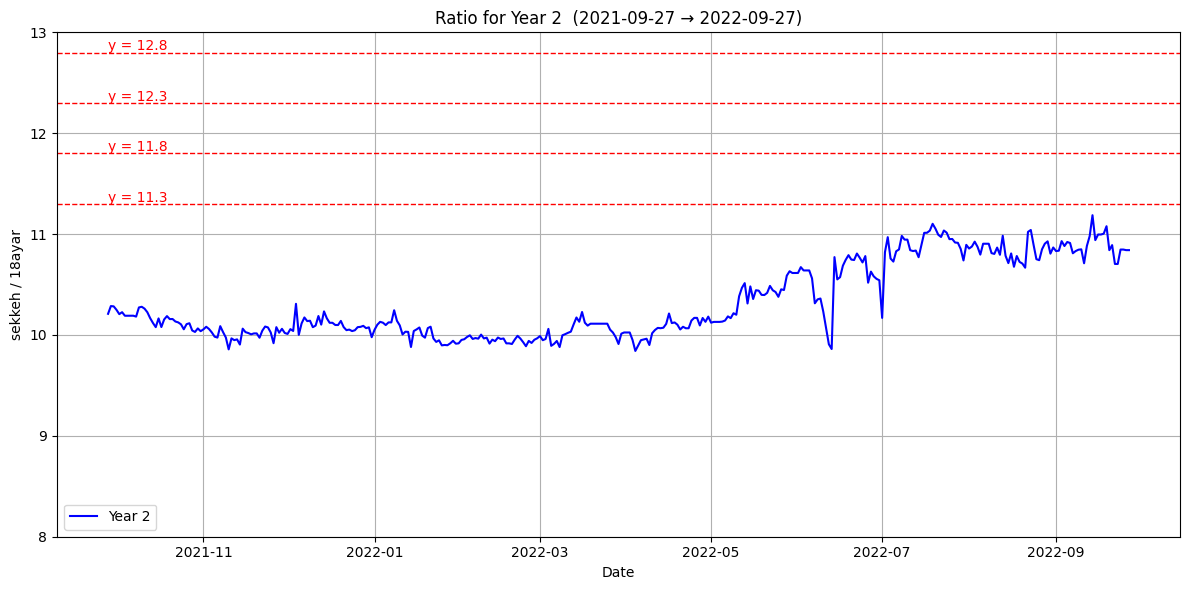

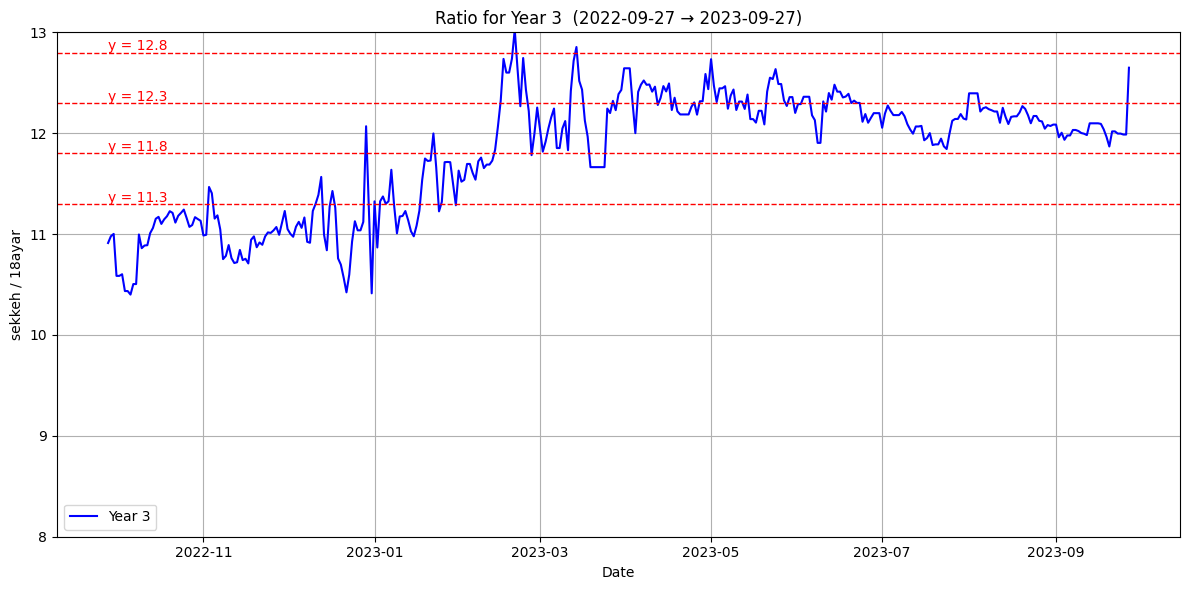

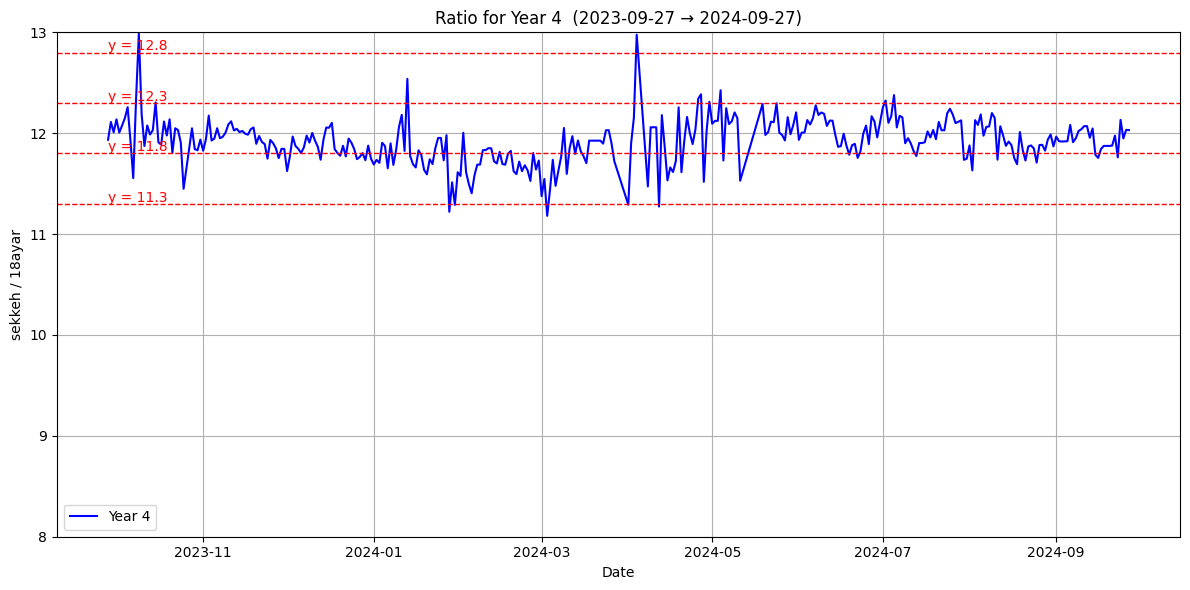

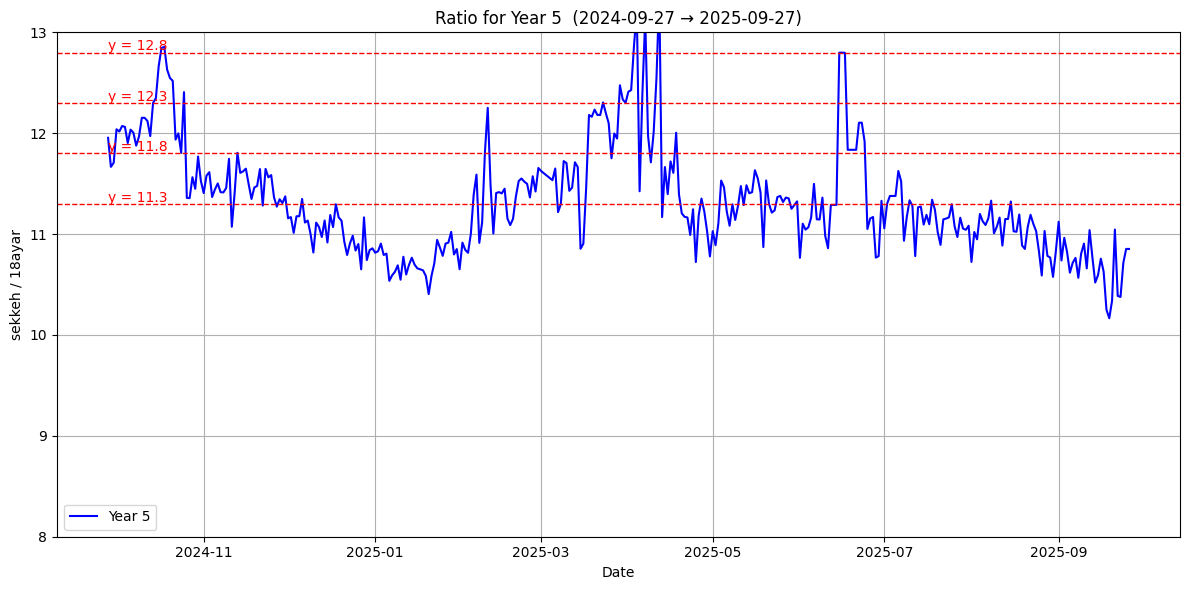

In [48]:
### Last 4 yeares, separeted years

import pandas as pd
import matplotlib.pyplot as plt

# Ensure ratio index is datetime
ratio.index = pd.to_datetime(ratio.index)

today = pd.Timestamp.today()

# Create a list of (start, end) tuples for each 1-year window
periods = [
    (today - pd.DateOffset(years=i+1), today - pd.DateOffset(years=i))
    for i in range(5)
]
periods = periods[::-1]


for i, (start, end) in enumerate(periods, start=1):
    # Filter data for this 1-year window
    window = ratio[(ratio.index >= start) & (ratio.index < end)]

    plt.figure(figsize=(12, 6))
    plt.plot(window.index, window, label=f'Year {i}', color='blue')

    # Focus the y-axis
    plt.ylim(8, 13)

    # Add horizontal guide lines
    for y in [11.3, 11.8, 12.3, 12.8]:
        plt.axhline(y=y, color='red', linestyle='--', linewidth=1)
        plt.text(window.index.min(), y + 0.02, f'y = {y}', color='red')

    plt.xlabel('Date')
    plt.ylabel('sekkeh / 18ayar')
    plt.title(f'Ratio for Year {i}  ({start.date()} → {end.date()})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


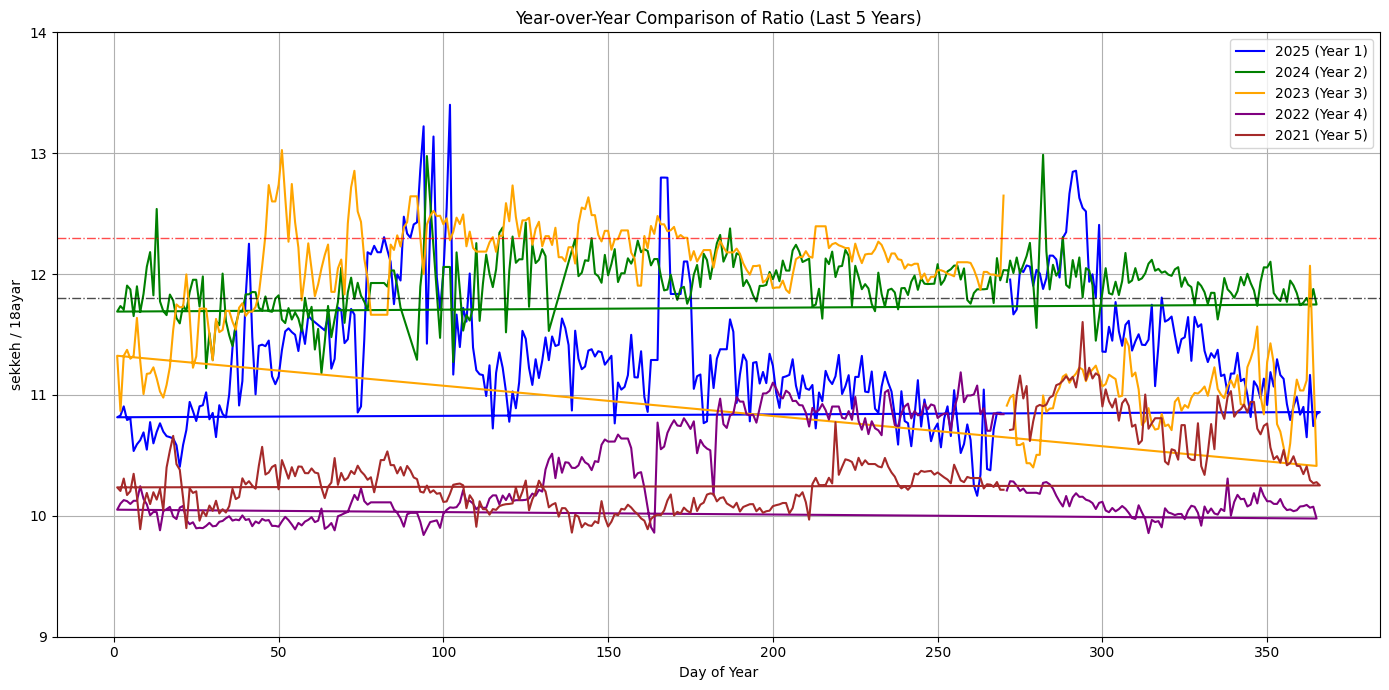

In [59]:
### All last 5 year on one chart

import pandas as pd
import matplotlib.pyplot as plt

# make sure ratio index is datetime
ratio.index = pd.to_datetime(ratio.index)

today = pd.Timestamp.today()

# create 5 one-year periods
periods = [
    (today - pd.DateOffset(years=i+1), today - pd.DateOffset(years=i))
    for i in range(5)
]

colors = ['blue', 'green', 'orange', 'purple', 'brown']

plt.figure(figsize=(14, 7))

for i, ((start, end), color) in enumerate(zip(periods, colors), start=1):
    # slice for that 1-year period
    window = ratio[(ratio.index >= start) & (ratio.index < end)]

    # convert each date to day-of-year
    x = window.index.dayofyear
    y = window.values

    # plot all on same x-axis (day of year)
    plt.plot(x, y, color=color, label=f'{end.year} (Year {i})')

# set y-axis focus
plt.ylim(9, 14)

# add horizontal guide lines
for y_line in [11.8, 12.3]:
    color = 'red' if y_line == 12.3 else 'black'
    plt.axhline(y=y_line, color=color, linestyle='-.', linewidth=1, alpha=0.7)

plt.xlabel('Day of Year')
plt.ylabel('sekkeh / 18ayar')
plt.title('Year-over-Year Comparison of Ratio (Last 5 Years)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### bubble of sekke and 18ayar

### dollar * ounce